[INFO] Loaded 12 operation recordings
calib file used : gyro_calibration_20260324_150747.pkl
calib file used : gyro_calibration_20260324_150859.pkl
calib file used : gyro_calibrations/gyro_calibration_20260324_150859.pkl
calib file used : gyro_calibrations/gyro_calibration_20260324_150859.pkl
calib file used : gyro_calibrations/gyro_calibration_20260324_150859.pkl
calib file used : gyro_calibrations/gyro_calibration_20260324_150859.pkl
calib file used : gyro_calibrations/gyro_calibration_20260324_150859.pkl
calib file used : gyro_calibrations/gyro_calibration_20260324_150859.pkl
calib file used : gyro_calibrations/gyro_calibration_20260324_150859.pkl
calib file used : gyro_calibrations/gyro_calibration_20260324_150859.pkl
calib file used : gyro_calibrations/gyro_calibration_20260324_150859.pkl
calib file used : gyro_calibrations/gyro_calibration_20260324_150859.pkl


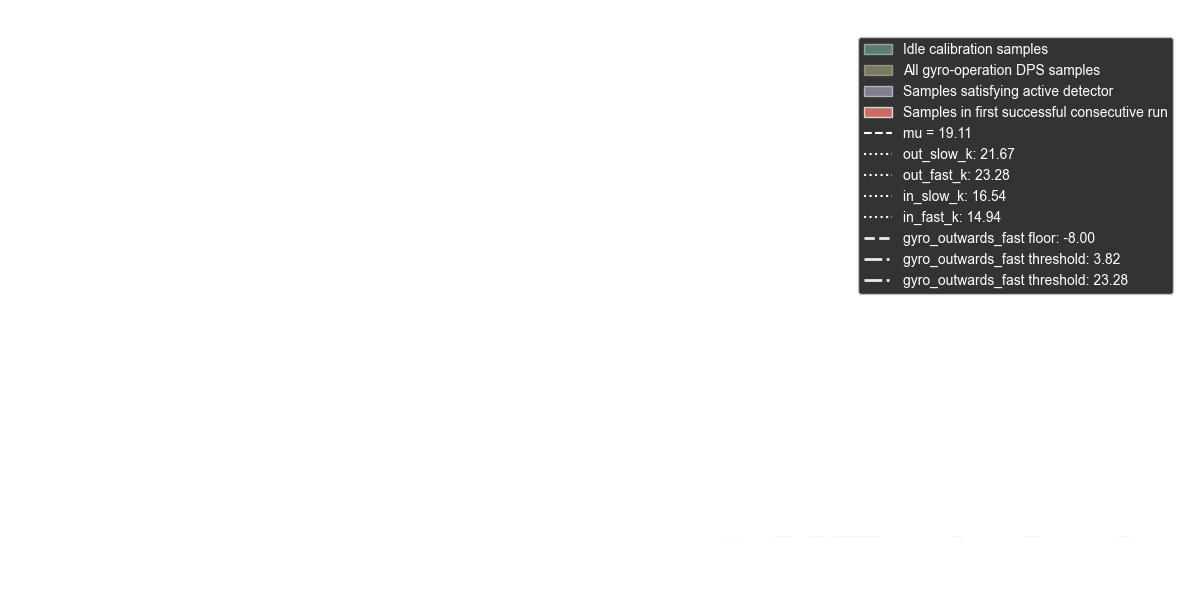

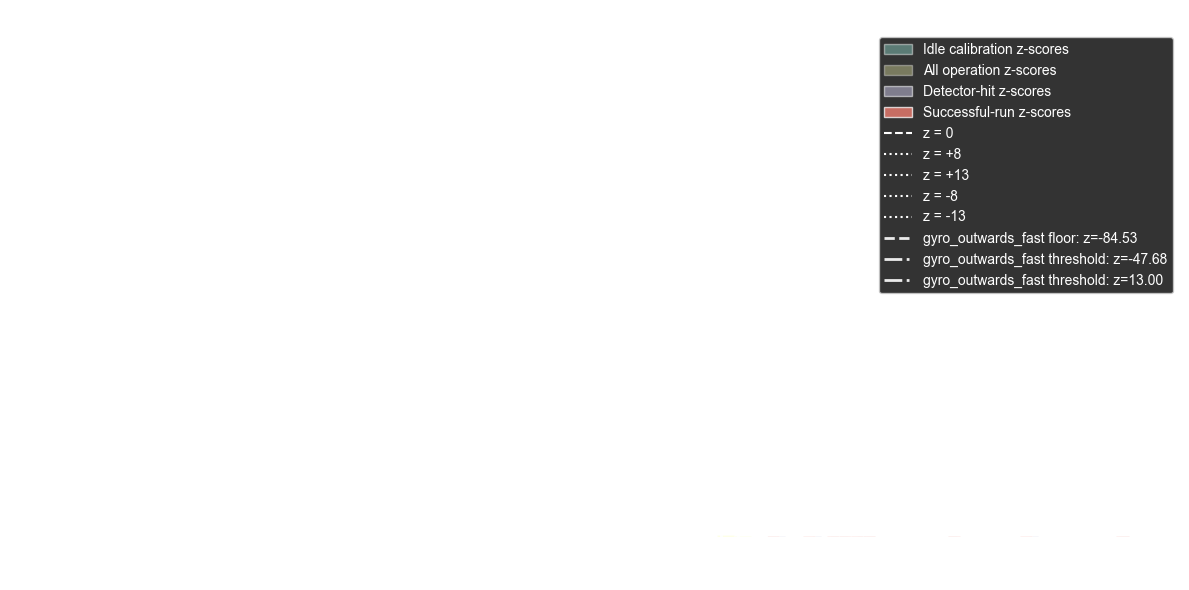

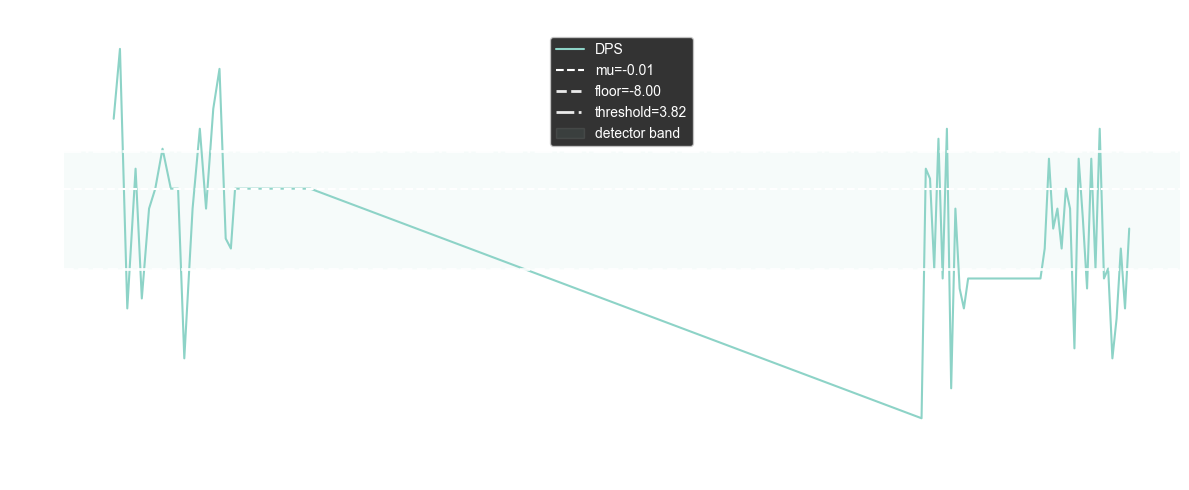

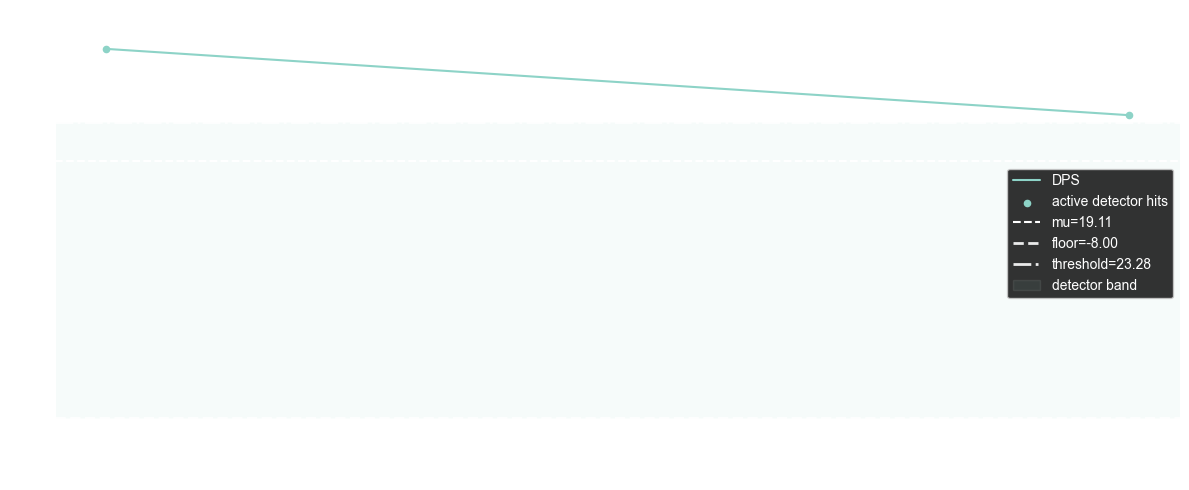

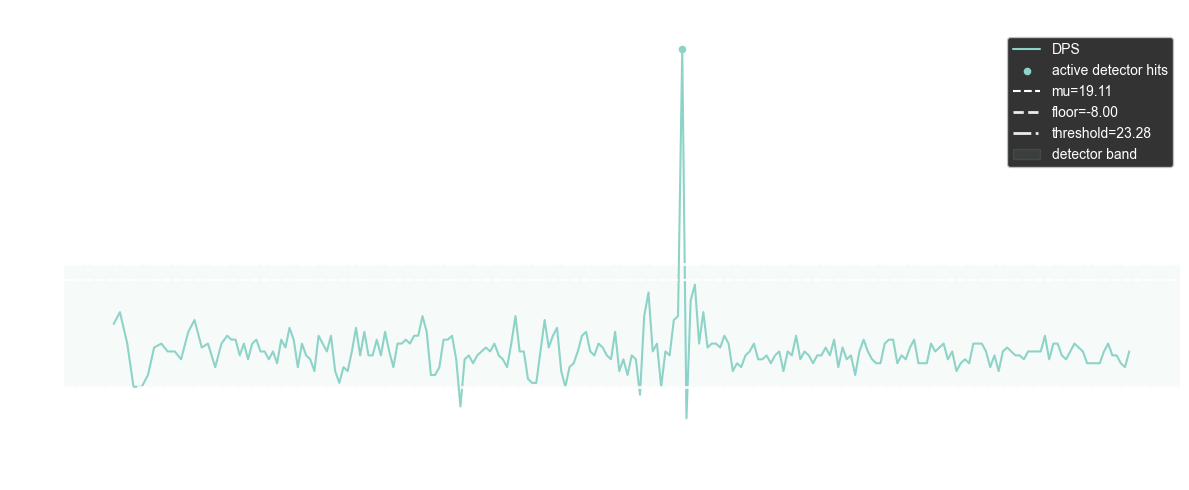

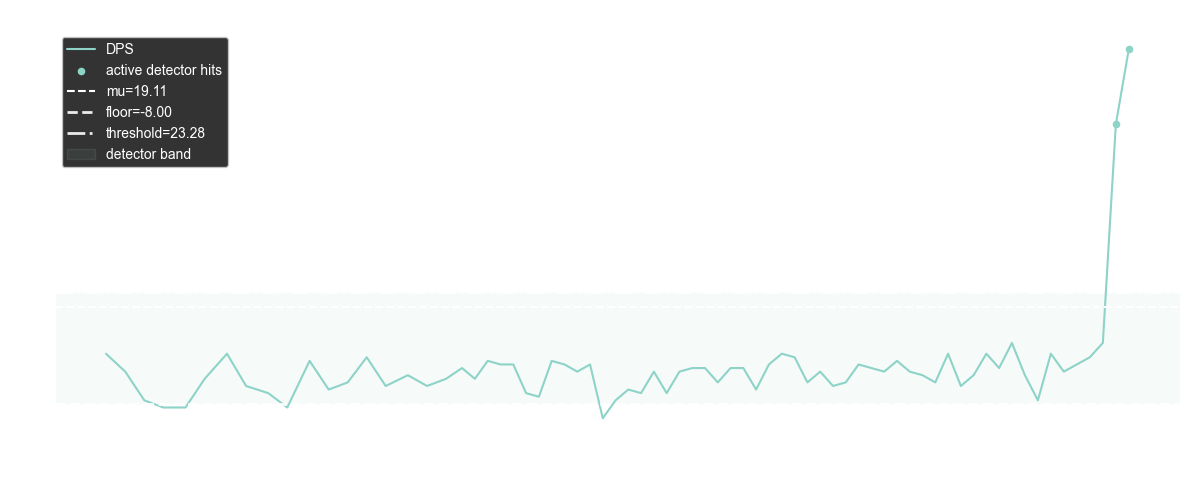

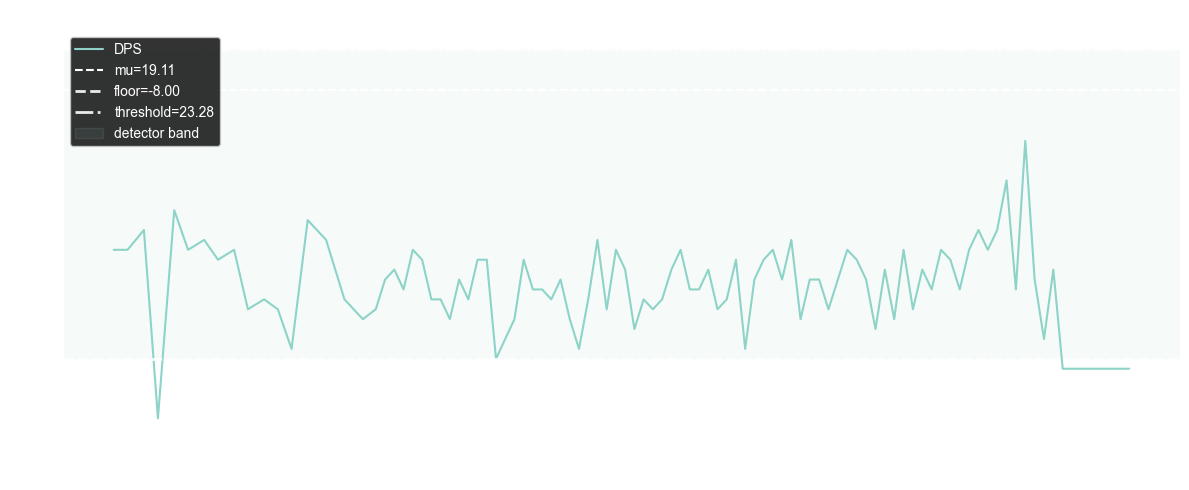

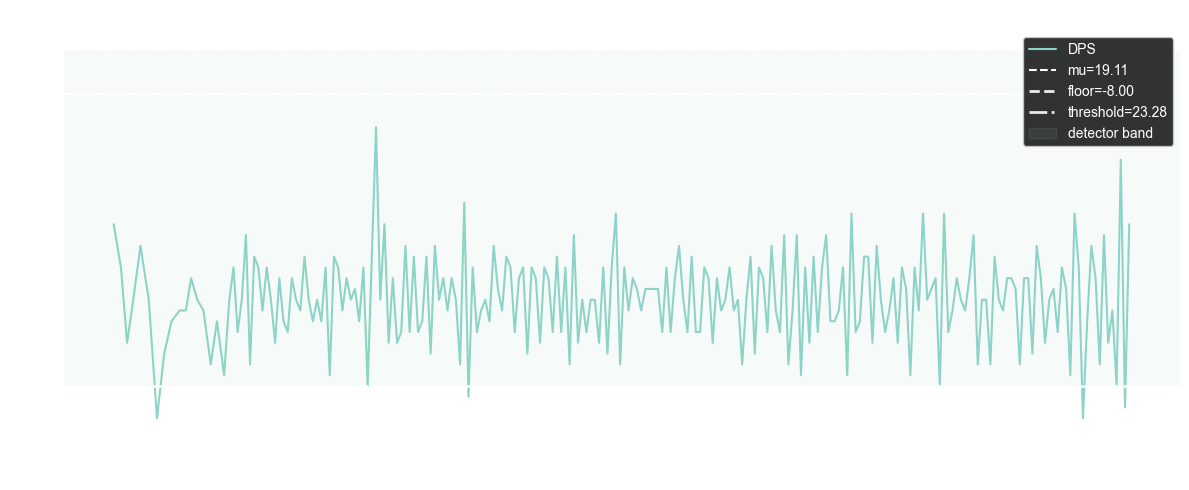

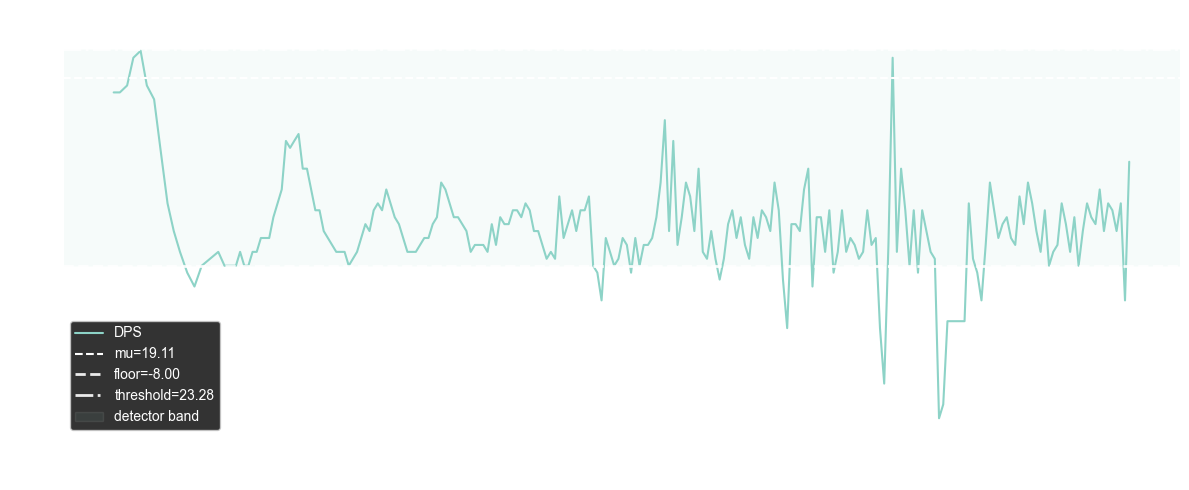

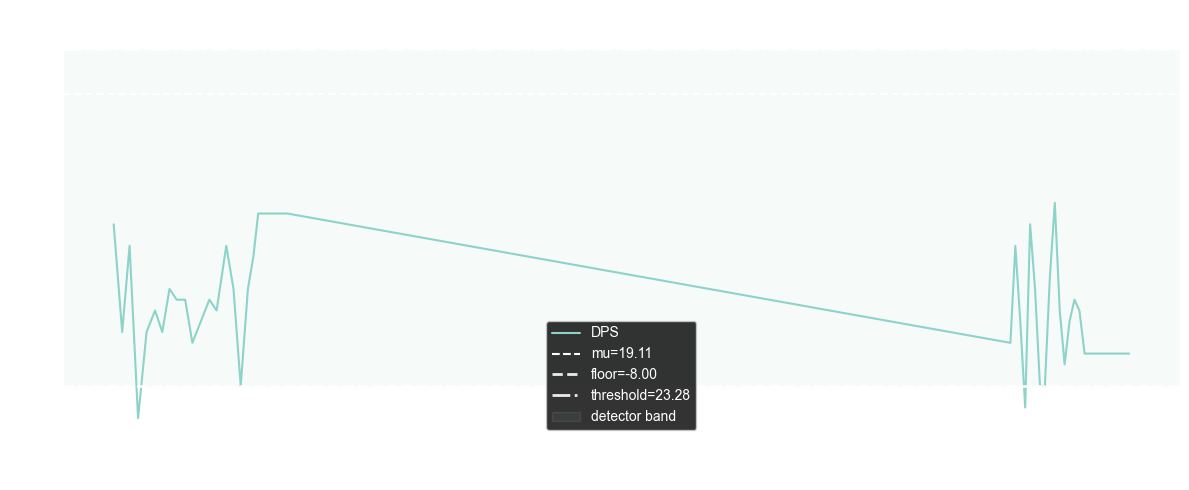

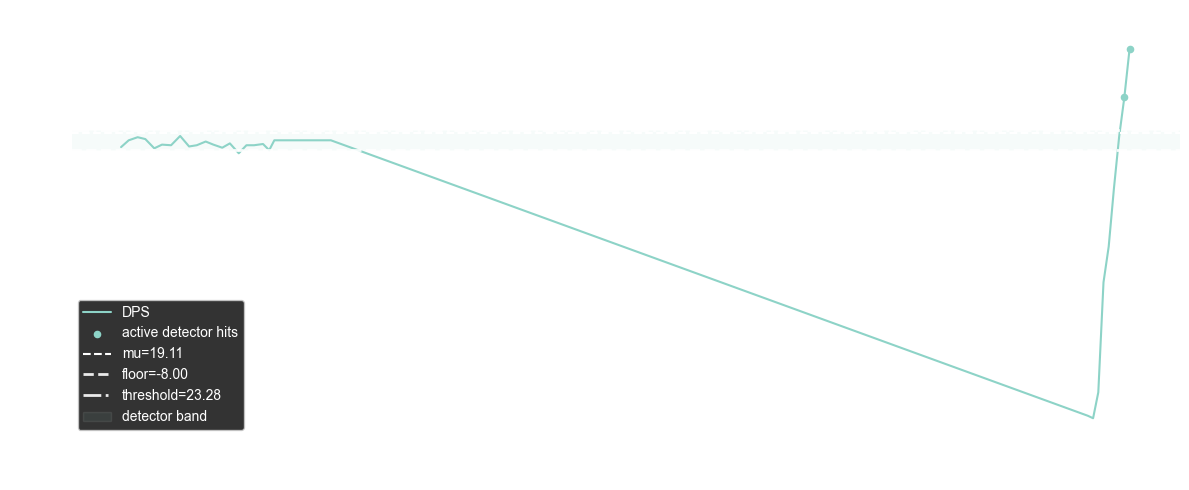

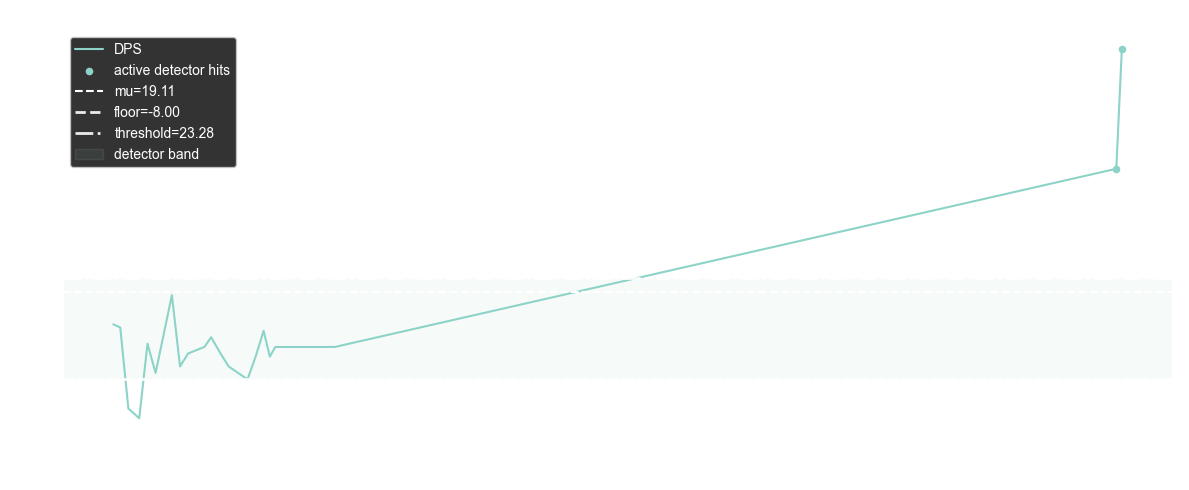

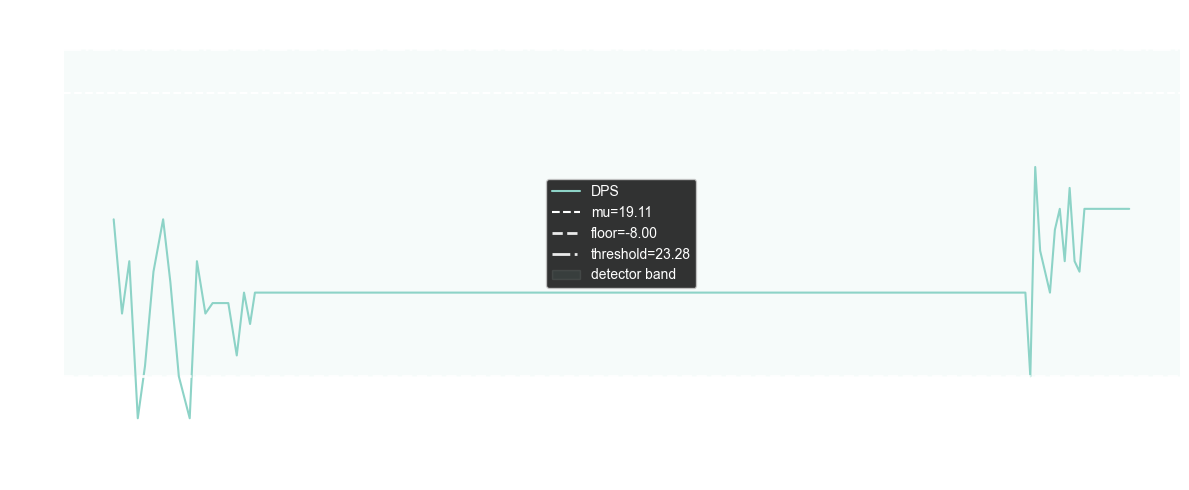

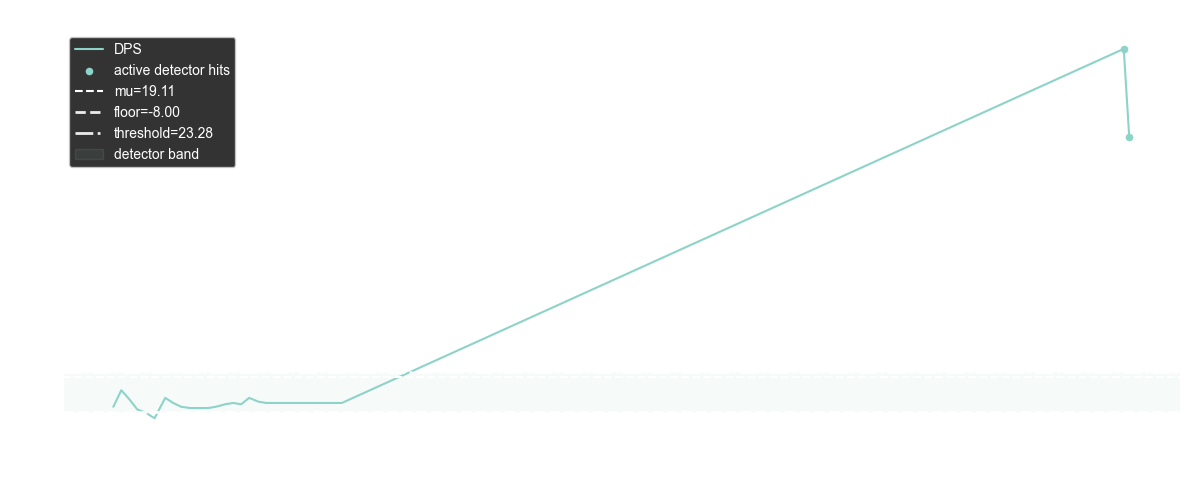

In [3]:
#!/usr/bin/env python3
import os
import glob
import pickle
from collections import defaultdict

import matplotlib.pyplot as plt


CALIBRATION_DIR = "gyro_calibrations"
RECORDINGS_DIR = "gyro_operation_recordings"


def load_operation_records(recordings_dir=RECORDINGS_DIR):
    #files = ["gyro_operation_recordings/load_first_bloc_20260324_153915.pkl"]
    files = sorted(glob.glob(os.path.join(recordings_dir, "*.pkl")))
    records = []

    for path in files:
        with open(path, "rb") as fh:
            rec = pickle.load(fh)
        rec["_path"] = path
        records.append(rec)

    print(f"[INFO] Loaded {len(records)} operation recordings")
    return records


def is_gyro_record(rec):
    return isinstance(rec, dict) and "samples" in rec and "mu" in rec and "sigma" in rec


def get_detector_hits(samples):
    return [s for s in samples if s.get("detectors", {}).get("active_detector", False)]


def get_first_consecutive_run(samples, needed):
    """
    Return the first run of `needed` consecutive active_detector=True samples.
    If none exists, return [].
    """
    run = []
    for s in samples:
        if s.get("detectors", {}).get("active_detector", False):
            run.append(s)
            if len(run) >= needed:
                return run[-needed:]
        else:
            run = []
    return []


def infer_k_lines(mu, sigma):
    return {
        "out_slow_k": mu + 8.0 * sigma,
        "out_fast_k": mu + 13.0 * sigma,
        "in_slow_k": mu - 8.0 * sigma,
        "in_fast_k": mu - 13.0 * sigma,
    }


def safe_float(x):
    if x is None:
        return None
    try:
        return float(x)
    except (TypeError, ValueError):
        return None


def add_unique_vertical_lines(ax, items, label_kind, mu=None, sigma=None, use_z=False):
    """
    items: list of (detector_name, value)
    label_kind: "floor" or "threshold"
    use_z: if True, convert value to z-score using mu/sigma
    """
    seen = set()
    linestyle = "--" if label_kind == "floor" else "-."
    linewidth = 2.0

    for detector_name, value in items:
        if use_z:
            if sigma is None or sigma == 0:
                continue
            x = (value - mu) / sigma
        else:
            x = value

        key = (detector_name, round(x, 4))
        if key in seen:
            continue
        seen.add(key)

        label = (
            f"{detector_name} {label_kind}: z={x:.2f}"
            if use_z
            else f"{detector_name} {label_kind}: {x:.2f}"
        )
        ax.axvline(x, linestyle=linestyle, linewidth=linewidth, alpha=0.9, label=label)


def main():
    records = [r for r in load_operation_records() if is_gyro_record(r)]

    if not records:
        print("[WARN] No valid gyro records found")
        return

    all_operation_dps = []
    all_hit_dps = []
    needed_run_dps = []

    thresholds_seen = []
    floors_seen = []
    grouped = defaultdict(list)

    calibration_samples = None
    mu, sigma = 0.0, 1.0

    # For better z-space aggregation, compute per-record z-values
    all_operation_z = []
    all_hit_z = []
    needed_run_z = []

    for rec in records:
        print("calib file used :", rec.get("gyro_calibration"))

        calib_path = rec.get("gyro_calibration")
        if calib_path and os.path.exists(calib_path):
            with open(calib_path, "rb") as fh:
                calib = pickle.load(fh)
            rec_mu = float(calib["mu"])
            rec_sigma = max(float(calib["sigma"]), 1e-6)
            rec_calibration_samples = calib.get("samples", None)

            # Keep the last one for the histogram overlay reference,
            # assuming single calibration or acceptable shared reference.
            mu = rec_mu
            sigma = rec_sigma
            calibration_samples = rec_calibration_samples
        else:
            rec_mu = float(rec.get("mu", 0.0))
            rec_sigma = max(float(rec.get("sigma", 1.0)), 1e-6)

        samples = rec.get("samples", [])
        extra = rec.get("extra", {}) or {}
        needed = int(extra.get("needed", 1))

        dps_vals = [float(s["dps"]) for s in samples if "dps" in s]
        hit_samples = get_detector_hits(samples)
        hit_dps = [float(s["dps"]) for s in hit_samples if "dps" in s]

        first_needed_run = get_first_consecutive_run(samples, needed)
        first_needed_run_dps = [float(s["dps"]) for s in first_needed_run if "dps" in s]

        all_operation_dps.extend(dps_vals)
        all_hit_dps.extend(hit_dps)
        needed_run_dps.extend(first_needed_run_dps)

        all_operation_z.extend([(x - rec_mu) / rec_sigma for x in dps_vals])
        all_hit_z.extend([(x - rec_mu) / rec_sigma for x in hit_dps])
        needed_run_z.extend([(x - rec_mu) / rec_sigma for x in first_needed_run_dps])

        detector_name = extra.get("detector", "unknown")
        grouped[detector_name].append(rec)

        thr = safe_float(extra.get("detector_threshold", None))
        floor = safe_float(extra.get("detector_floor", None))

        if thr is not None:
            thresholds_seen.append((detector_name, thr))

        if floor is not None:
            floors_seen.append((detector_name, floor))

    # ---------- Plot 1: Histogram overlay ----------
    fig1, ax1 = plt.subplots(figsize=(12, 6), facecolor="white")
    ax1.set_facecolor("white")

    if calibration_samples:
        ax1.hist(
            calibration_samples,
            bins=60,
            alpha=0.45,
            density=True,
            label="Idle calibration samples"
        )

    if all_operation_dps:
        ax1.hist(
            all_operation_dps,
            bins=60,
            alpha=0.35,
            density=True,
            label="All gyro-operation DPS samples"
        )

    if all_hit_dps:
        ax1.hist(
            all_hit_dps,
            bins=40,
            alpha=0.55,
            density=True,
            label="Samples satisfying active detector"
        )

    if needed_run_dps:
        ax1.hist(
            needed_run_dps,
            bins=30,
            alpha=0.75,
            density=True,
            label="Samples in first successful consecutive run"
        )

    ax1.axvline(mu, linestyle="--", linewidth=1.5, label=f"mu = {mu:.2f}")

    k_lines = infer_k_lines(mu, sigma)
    for name, x in k_lines.items():
        ax1.axvline(x, linestyle=":", linewidth=1.5, label=f"{name}: {x:.2f}")

    add_unique_vertical_lines(ax1, floors_seen, "floor", use_z=False)
    add_unique_vertical_lines(ax1, thresholds_seen, "threshold", use_z=False)

    ax1.set_xlabel("Gyro DPS")
    ax1.set_ylabel("Density")
    ax1.set_title("Where event-triggering gyro samples fall relative to calibration distribution")
    ax1.grid(True)
    ax1.legend()
    fig1.tight_layout()

    # ---------- Plot 2: z-score overlay ----------
    fig2, ax2 = plt.subplots(figsize=(12, 6), facecolor="white")
    ax2.set_facecolor("white")

    if calibration_samples:
        calib_z = [(x - mu) / sigma for x in calibration_samples]
        ax2.hist(calib_z, bins=60, alpha=0.45, density=True, label="Idle calibration z-scores")

    if all_operation_z:
        ax2.hist(all_operation_z, bins=60, alpha=0.35, density=True, label="All operation z-scores")

    if all_hit_z:
        ax2.hist(all_hit_z, bins=40, alpha=0.55, density=True, label="Detector-hit z-scores")

    if needed_run_z:
        ax2.hist(needed_run_z, bins=30, alpha=0.75, density=True, label="Successful-run z-scores")

    ax2.axvline(0.0, linestyle="--", linewidth=1.5, label="z = 0")
    ax2.axvline(8.0, linestyle=":", linewidth=1.5, label="z = +8")
    ax2.axvline(13.0, linestyle=":", linewidth=1.5, label="z = +13")
    ax2.axvline(-8.0, linestyle=":", linewidth=1.5, label="z = -8")
    ax2.axvline(-13.0, linestyle=":", linewidth=1.5, label="z = -13")

    add_unique_vertical_lines(ax2, floors_seen, "floor", mu=mu, sigma=sigma, use_z=True)
    add_unique_vertical_lines(ax2, thresholds_seen, "threshold", mu=mu, sigma=sigma, use_z=True)

    ax2.set_xlabel("z = (dps - mu) / sigma")
    ax2.set_ylabel("Density")
    ax2.set_title("Event-triggering samples in z-score space")
    ax2.grid(True)
    ax2.legend()
    fig2.tight_layout()

    # ---------- Plot 3: Per-record trace with floor + threshold ----------
    for rec in records:
        samples = rec.get("samples", [])
        if not samples:
            continue

        t = [s["t"] for s in samples if "t" in s and "dps" in s]
        dps = [s["dps"] for s in samples if "t" in s and "dps" in s]
        active = [
            s.get("detectors", {}).get("active_detector", False)
            for s in samples
            if "t" in s and "dps" in s
        ]

        extra = rec.get("extra", {}) or {}
        thr = safe_float(extra.get("detector_threshold", None))
        floor = safe_float(extra.get("detector_floor", None))
        needed = extra.get("needed", None)

        fig, ax = plt.subplots(figsize=(12, 5), facecolor="white")
        ax.set_facecolor("white")

        ax.plot(t, dps, label="DPS")

        hit_t = [tt for tt, a in zip(t, active) if a]
        hit_d = [dd for dd, a in zip(dps, active) if a]
        if hit_t:
            ax.scatter(hit_t, hit_d, label="active detector hits", s=20)

        rec_mu = float(rec.get("mu", 0.0))
        ax.axhline(rec_mu, linestyle="--", linewidth=1.5, label=f"mu={rec_mu:.2f}")

        if floor is not None:
            ax.axhline(
                floor,
                linestyle="--",
                linewidth=2.0,
                alpha=0.9,
                label=f"floor={floor:.2f}"
            )

        if thr is not None:
            ax.axhline(
                thr,
                linestyle="-.",
                linewidth=2.0,
                alpha=0.9,
                label=f"threshold={thr:.2f}"
            )

        if floor is not None and thr is not None and floor != thr:
            band_low = min(floor, thr)
            band_high = max(floor, thr)
            ax.axhspan(band_low, band_high, alpha=0.08, label="detector band")

        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Gyro DPS")
        ax.set_title(
            f"{rec.get('operation')} | {rec.get('outcome')} | "
            f"{extra.get('detector', 'unknown')} | needed={needed}"
        )
        ax.grid(True)
        ax.legend()
        fig.tight_layout()

    plt.show()


if __name__ == "__main__":
    main()